# Linear inverse problems with a Gaussian-mixture prior
        The posterior remains a mixture. Observation evidence updates its weights,
        and total covariance includes within- and between-component uncertainty.
        [Derivation and archive audit](../docs/10_course_projects.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

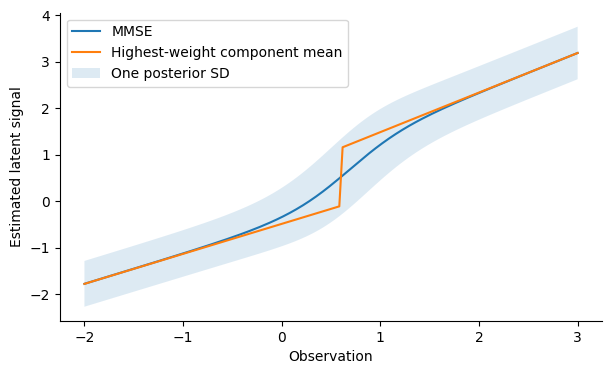

In [2]:
from learning_lab.inverse import MixtureInverse, extract_patches, overlap_average
prior = MixtureInverse([.7,.3], [[-1.],[2.]], [[[.5]],[[1.]]], [[.8]], .3)
y = np.linspace(-2,3,150)[:,None]
p = prior.condition(y, return_covariance=True)
fig, ax = plt.subplots()
ax.plot(y[:,0],p['mmse'][:,0],label='MMSE')
ax.plot(y[:,0],p['hard'][:,0],label='Highest-weight component mean')
sd = np.sqrt(p['covariance'][:,0,0])
ax.fill_between(y[:,0],p['mmse'][:,0]-sd,p['mmse'][:,0]+sd,alpha=.15,label='One posterior SD')
ax.set(xlabel='Observation',ylabel='Estimated latent signal'); ax.legend(); plt.show()

The shaded band describes posterior standard deviation, not a calibrated
        confidence interval or a Gaussian approximation justified for every mixture.
        A highest-weight component mean is not the general mixture MAP.

In [3]:
x = np.random.default_rng(0).normal(size=(3,28,28))
for size in [4,8,12,16,20,28]:
    np.testing.assert_allclose(overlap_average(extract_patches(x,size), x.shape,size), x, atol=1e-13)
print('Patch overlap reconstruction verified, including all boundary pixels.')

Patch overlap reconstruction verified, including all boundary pixels.


In [4]:
m = evidence('inverse')
pd.DataFrame(m['controlled'])[['m','k','method','test_psnr']]

,m,k,method,test_psnr
0,4,12,mmse,28.368538
1,4,12,hard,28.406008
2,8,12,mmse,25.891688
3,8,12,hard,25.895915
4,12,12,mmse,23.669576
5,12,12,hard,23.670038
6,16,12,mmse,22.696538
7,16,12,hard,22.697247
8,20,12,mmse,22.329896
9,20,12,hard,22.329983


In [5]:
pd.DataFrame([{'actual_m':r['actual_m'],'raw_psnr':r['test_raw_psnr'],
              'nominal_mmse':r['test_mmse_psnr'],'calibrated_mmse':r['test_calibrated_psnr'],
              'residual_mean_255':r['observation_residual_mean_255']} for r in m['supplied']])

,actual_m,raw_psnr,nominal_mmse,calibrated_mmse,residual_mean_255
0,16,10.667187,9.439175,18.271676,69.781208
1,20,10.579940,10.539812,17.568550,64.711068
2,28,8.811031,10.206017,12.921560,82.322445
3,4,9.385435,4.065410,18.863984,93.316696
4,12,10.305601,8.586890,18.359713,75.829038


## Worked answer
        Why not score an observed patch under a clean-patch posterior? These distributions
        concern different variables. Component evidence is the marginal observation density
        with mean Aμ+b and covariance ACAᵀ+R. The supplied PNGs also violate the nominal
        zero-mean Gaussian model; calibration uses separate validation pairs, never test pairs.
        An individual test image may favor a hard estimator when the prior is misspecified.